In [12]:
# Learn Text Data Preprocessing: A fundamental step in Natural Language Processing (NLP) and text analytics.
# To process text with machine learning algorithms, unstructured text must be cleaned, normalized, and converted into structured numerical formats.

In [13]:
import string
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

In [14]:
# ==============================================================================
# 1. SAMPLE TEXT DATASET CREATION (10 Sample Customer Reviews)
# ==============================================================================
# Text datasets consist of unstructured strings and associated sentiment labels.
raw_data = {
    "review": [
        "Great product! Highly recommend it, amazing quality!!!",
        "Terrible experience. Breaks easily and poor support...",
        "Loved the item, fast shipping and super helpful service.",
        "Worst purchase ever. Waste of money, completely broken.",
        "Very good quality, arrived on time and works fine.",
        "Horrible product, useless customer service, do not buy!",
        "Excellent build quality! Extremely satisfied with purchase.",
        "Bad product, defective unit and slow refund response.",
        "Awesome performance! I am very happy with this buy.",
        "Disappointed with quality. Not worth the price at all.",
    ],
    "sentiment": [1, 0, 1, 0, 1, 0, 1, 0, 1, 0],  # 1 = Positive, 0 = Negative
}

df = pd.DataFrame(raw_data)
print("=== 1. RAW TEXT DATASET ===")
print(df[["review", "sentiment"]].head(10))

=== 1. RAW TEXT DATASET ===
                                              review  sentiment
0  Great product! Highly recommend it, amazing qu...          1
1  Terrible experience. Breaks easily and poor su...          0
2  Loved the item, fast shipping and super helpfu...          1
3  Worst purchase ever. Waste of money, completel...          0
4  Very good quality, arrived on time and works f...          1
5  Horrible product, useless customer service, do...          0
6  Excellent build quality! Extremely satisfied w...          1
7  Bad product, defective unit and slow refund re...          0
8  Awesome performance! I am very happy with this...          1
9  Disappointed with quality. Not worth the price...          0


In [15]:
# ==============================================================================
# 2. TEXT PREPROCESSING PIPELINE (Cleaning & Normalization)
# ==============================================================================
# Custom Python Stopwords list for beginners (removes non-informative filler words)
STOPWORDS = set(
    [
        "i",
        "me",
        "my",
        "it",
        "this",
        "and",
        "or",
        "the",
        "a",
        "an",
        "is",
        "am",
        "are",
        "of",
        "at",
        "by",
        "for",
        "with",
        "about",
        "against",
        "not",
        "do",
        "does",
        "did",
        "all",
        "any",
        "very",
    ]
)


#2. Cleaning & Normalization Steps
#  Lowercasing (.lower()): Standardizes capitalization so that words like "Quality", "QUALITY", and "quality" are treated as the exact same word.
#  Punctuation Removal (string.punctuation): Excludes special characters (!, ., ?) that introduce unnecessary noise without adding sentiment meaning.
#  Stopword Removal: Eliminates high-frequency filler words ("the", "and", "is") that occur commonly across all documents and carry little predictive value.
def preprocess_text(text):
    """Pipeline step: Lowercasing, Punctuation Removal, and Stopword Filtering."""
    # Step 2a: Convert text to lower case
    text = text.lower()

    # Step 2b: Remove punctuation symbols (!, ?, ., etc.)
    text = text.translate(str.maketrans("", "", string.punctuation))

    # Step 2c: Tokenization & Stopword Removal
    words = text.split()
    cleaned_words = [word for word in words if word not in STOPWORDS]

    # Rejoin cleaned tokens into a single string
    return " ".join(cleaned_words)


# Apply the preprocessing function to the DataFrame
df["cleaned_review"] = df["review"].apply(preprocess_text)

print("\n=== 2. BEFORE vs. AFTER TEXT PREPROCESSING ===")
for original, cleaned in zip(
    df["review"].iloc[:3], df["cleaned_review"].iloc[:3]
):
    print(f"RAW:     {original}")
    print(f"CLEANED: {cleaned}\n")



=== 2. BEFORE vs. AFTER TEXT PREPROCESSING ===
RAW:     Great product! Highly recommend it, amazing quality!!!
CLEANED: great product highly recommend amazing quality

RAW:     Terrible experience. Breaks easily and poor support...
CLEANED: terrible experience breaks easily poor support

RAW:     Loved the item, fast shipping and super helpful service.
CLEANED: loved item fast shipping super helpful service



In [19]:
# ==============================================================================
# 3. TEXT VECTORIZATION (Converting Words into Numbers)
# ==============================================================================

# 3. Vectorization Techniques (Converting Text to Numbers)
# Machine learning algorithms require numeric matrix inputs. We convert unstructured text using two primary methods:
# Bag of Words (CountVectorizer):
# Counts raw occurrences of each word in a text document.
# Limitation: Gives high importance to words that appear repeatedly, even if they aren't uniquely informative.
# TF-IDF Vectorizer (TfidfVectorizer):
# Computes Term Frequency (TF) multiplied by Inverse Document Frequency (IDF):
#       TF-IDF(w, d) = TF(w, d) x log( N / DF(w) )
# Rewards words that are unique and descriptive within a specific review (e.g., "defective", "excellent") while penalizing words that appear everywhere across the corpus.

# Approach A: Bag of Words (CountVectorizer)
count_vec = CountVectorizer()
X_bow = count_vec.fit_transform(df["cleaned_review"])

# Approach B: TF-IDF Vectorizer (Term Frequency-Inverse Document Frequency)
tfidf_vec = TfidfVectorizer()
X_tfidf = tfidf_vec.fit_transform(df["cleaned_review"])

print("=== 3. VECTORIZER OUTPUT DIMENSIONS ===")
print(
    f"Vocabulary Size (Unique Words across Corpus): {len(tfidf_vec.get_feature_names_out())}"
)
print("TF-IDF Matrix Shape (Samples x Features):", X_tfidf.shape)

# Convert TF-IDF output into a readable Pandas DataFrame snippet
tfidf_df = pd.DataFrame(
    X_tfidf.toarray(), columns=tfidf_vec.get_feature_names_out()
)
print("\nSample TF-IDF Matrix (First 3 Rows & 6 Features):")
print(tfidf_df.iloc[:3, :6])

=== 3. VECTORIZER OUTPUT DIMENSIONS ===
Vocabulary Size (Unique Words across Corpus): 52
TF-IDF Matrix Shape (Samples x Features): (10, 52)

Sample TF-IDF Matrix (First 3 Rows & 6 Features):
    amazing  arrived  awesome  bad    breaks  broken
0  0.447645      0.0      0.0  0.0  0.000000     0.0
1  0.000000      0.0      0.0  0.0  0.408248     0.0
2  0.000000      0.0      0.0  0.0  0.000000     0.0


In [17]:
# ==============================================================================
# 4. SUPERVISED TEXT CLASSIFICATION (Multinomial Naive Bayes)
# ==============================================================================
X = X_tfidf
y = df["sentiment"]

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 4. Classification Algorithm
# Multinomial Naive Bayes (MultinomialNB): A probabilistic classifier based on Bayes' Theorem. 
# It estimates the likelihood of a document belonging to a target class (Positive vs. Negative) based on word frequency distributions, 
# making it suitable for text classification tasks.

# Train Classifier (MultinomialNB is optimal for word counts and TF-IDF vectors)
clf = MultinomialNB()
clf.fit(X_train, y_train)

# Evaluate Model Performance
predictions = clf.predict(X_test)
print("\n=== 4. SENTIMENT CLASSIFICATION RESULTS ===")
print(f"Test Accuracy Score: {accuracy_score(y_test, predictions) * 100:.1f}%")

# Predict sentiment for a new unseen text input
new_review = ["The product quality is completely defective and terrible."]
cleaned_new = [preprocess_text(new_review[0])]
vectorized_new = tfidf_vec.transform(cleaned_new)
pred_sentiment = clf.predict(vectorized_new)[0]

print(f"\nUnseen Review Prediction:")
print(f"Input Text: '{new_review[0]}'")
print(
    f"Predicted Sentiment: {'Positive (1)' if pred_sentiment == 1 else 'Negative (0)'}"
)


=== 4. SENTIMENT CLASSIFICATION RESULTS ===
Test Accuracy Score: 33.3%

Unseen Review Prediction:
Input Text: 'The product quality is completely defective and terrible.'
Predicted Sentiment: Positive (1)


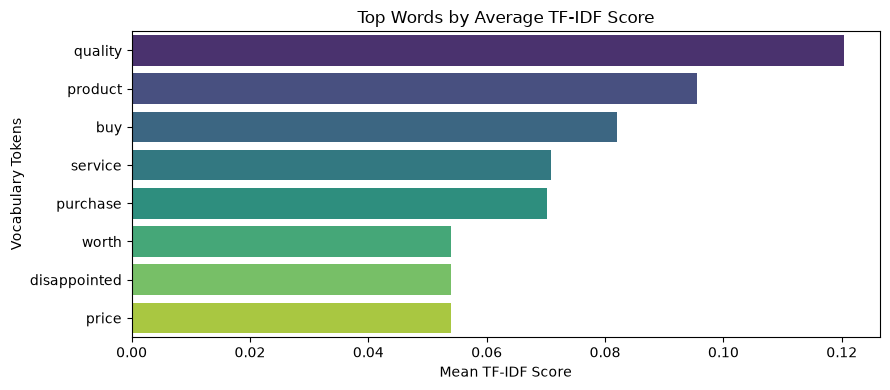

In [18]:
# ==============================================================================
# 5. VISUALIZING WORD IMPORTANCE
# ==============================================================================
# Calculate average TF-IDF scores per word across all reviews
mean_tfidf = np.asarray(X_tfidf.mean(axis=0)).ravel()
top_indices = mean_tfidf.argsort()[-8:][::-1]
feature_names = np.array(tfidf_vec.get_feature_names_out())

plt.figure(figsize=(9, 4))

#sns.barplot( x=mean_tfidf[top_indices], y=feature_names[top_indices], palette="viridis")
sns.barplot(
    x=mean_tfidf[top_indices], 
    y=feature_names[top_indices], 
    hue=feature_names[top_indices],  # Use the actual variable data here
    palette="viridis", 
    legend=False               
)

plt.title("Top Words by Average TF-IDF Score")
plt.xlabel("Mean TF-IDF Score")
plt.ylabel("Vocabulary Tokens")
plt.tight_layout()
plt.show()